In [167]:
#Entrenamiento de modelos de Machine Learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modelos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Validación y clonación
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Métricas
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Persistencia
import joblib

# Configuración global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo de gráficos
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas correctamente")
print(f"   - numpy: {np.__version__}")
print(f"   - pandas: {pd.__version__}")
print(f"   - scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerías importadas correctamente
   - numpy: 2.4.6
   - pandas: 2.2.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [168]:
!git clone https://github.com/sebaas256/Proyecto_final_gestion_de_datos_IA.git


fatal: destination path 'Proyecto_final_gestion_de_datos_IA' already exists and is not an empty directory.


In [169]:
# ============================================================
# CELDA 2: Reconstruir dataset desde Excel
# ============================================================
import pandas as pd

# 1. Cargar el dataset limpio
ruta_archivo = "/content/Proyecto_final_gestion_de_datos_IA/content/datos/procesados/dataset_final_limpio.xlsx"
df_raw = pd.read_excel(ruta_archivo)

# 2. Asegurar tipo datetime y agrupar a nivel diario
df_raw["event_date"] = pd.to_datetime(df_raw["event_date"])

df_diario = (
    df_raw.groupby("event_date")
    .agg(
        {
            "ticket_count": "sum",
            "deployment_count": "sum",
            "incident_count": "sum",
            "avg_response_time_ms": "mean",
            "avg_error_rate_pct": "mean",
        }
    )
    .reset_index()
    .sort_values("event_date")
)

# 3. Feature Engineering Temporal
df_diario["dia_semana"] = df_diario["event_date"].dt.dayofweek
df_diario["mes"] = df_diario["event_date"].dt.month
df_diario["es_fin_semana"] = df_diario["dia_semana"].isin([5, 6]).astype(int)

# 4. Lags y Media Móvil de 7 días sobre la variable objetivo (ticket_count)
df_diario["lag_1"] = df_diario["ticket_count"].shift(1)
df_diario["lag_7"] = df_diario["ticket_count"].shift(7)
df_diario["media_movil_7"] = (
    df_diario["ticket_count"].shift(1).rolling(7).mean()
)

# 5. Eliminar NaN iniciales
df_modelo = df_diario.dropna().copy()

print(
    f"Dataset reconstruido: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas"
)
print(f"Media tickets diarios: {df_modelo['ticket_count'].mean():,.2f}")
print(f"\nPrimeras 3 filas:")
print(df_modelo.head(3).to_string(index=False))

Dataset reconstruido: 174 filas, 12 columnas
Media tickets diarios: 275.98

Primeras 3 filas:
event_date  ticket_count  deployment_count  incident_count  avg_response_time_ms  avg_error_rate_pct  dia_semana  mes  es_fin_semana  lag_1  lag_7  media_movil_7
2026-01-08           281                81              24            260.932576            2.473924           3    1              0  311.0  292.0     282.857143
2026-01-09           268                80              19            229.963127            2.097205           4    1              0  281.0  287.0     281.285714
2026-01-10           285                93              24            326.039755            2.735550           5    1              1  268.0  279.0     278.571429


In [170]:
# ============================================================
# CELDA 3: Definir X, y y split 80/20 cronológico
# ============================================================

# Lista completa de predictores incluyendo métricas agregadas y temporales
features = [
    "deployment_count",
    "incident_count",
    "avg_response_time_ms",
    "avg_error_rate_pct",
    "dia_semana",
    "mes",
    "es_fin_semana",
    "lag_1",
    "lag_7",
    "media_movil_7",
]

X = df_modelo[features]
y = df_modelo["ticket_count"]

# Split cronológico 80/20
corte = int(len(df_modelo) * 0.80)

X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]
fecha_test = df_modelo["event_date"].iloc[corte:]

print("SPLIT CRONOLÓGICO 80/20")
print("=" * 55)
print(f"Entrenamiento: {X_train.shape}")
print(f"Prueba:        {X_test.shape}")
print(
    f"Última fecha train: {df_modelo['event_date'].iloc[corte-1].date()}"
)
print(f"Primera fecha test: {df_modelo['event_date'].iloc[corte].date()}")
print(
    f"¿Test después de train? {df_modelo['event_date'].iloc[corte] > df_modelo['event_date'].iloc[corte-1]}"
)

SPLIT CRONOLÓGICO 80/20
Entrenamiento: (139, 10)
Prueba:        (35, 10)
Última fecha train: 2026-05-26
Primera fecha test: 2026-05-27
¿Test después de train? True


In [171]:
# ============================================================
# CELDA 4: Catálogo de modelos candidatos
# ============================================================

modelos = {
    "Baseline media": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=5,          # Controla la profundidad para no memorizar el ruido
        min_samples_leaf=5,   # Mínimo de muestras por hoja para suavizar predicciones
        min_samples_split=10, # Mínimo de muestras para dividir un nodo
        random_state=RANDOM_STATE
    ),
}

print("MODELOS EN EL CATÁLOGO")
print("=" * 55)
for i, nombre in enumerate(modelos.keys(), 1):
    print(f"  {i}. {nombre}")

MODELOS EN EL CATÁLOGO
  1. Baseline media
  2. Regresión lineal
  3. Árbol de decisión
  4. Random Forest


In [172]:
# ============================================================
# CELDA 5: Función de métricas y evaluación holdout
# ============================================================


def metricas_regresion(y_real, y_pred):
    """Calcula MAE, RMSE y R²."""
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": mean_squared_error(y_real, y_pred) ** 0.5,
        "R2": r2_score(y_real, y_pred),
    }


def evaluar_holdout(nombre, estimador):
    """Entrena un modelo clonado, evalúa en train y test,

    y devuelve (modelo, fila_resultado, predicciones_test).
    """
    modelo = clone(estimador)
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    mt = metricas_regresion(y_train, pred_train)
    mp = metricas_regresion(y_test, pred_test)

    fila = {
        "Modelo": nombre,
        "MAE_train": mt["MAE"],
        "MAE_test": mp["MAE"],
        "RMSE_test": mp["RMSE"],
        "R2_test": mp["R2"],
        "Brecha_MAE": mp["MAE"] - mt["MAE"],
    }

    return modelo, fila, pred_test


print("Funciones definidas correctamente")

Funciones definidas correctamente


In [173]:
# ============================================================
# CELDA 6: Entrenar y evaluar todos los modelos (holdout)
# ============================================================

resultados_holdout = []
modelos_entrenados = {}
predicciones = {}

for nombre, estimador in modelos.items():
    modelo, fila, pred = evaluar_holdout(nombre, estimador)
    modelos_entrenados[nombre] = modelo
    predicciones[nombre] = pred
    resultados_holdout.append(fila)

tabla_holdout = pd.DataFrame(resultados_holdout)

print("RESULTADOS EN HOLDOUT (sin ordenar)")
print("=" * 75)
print(tabla_holdout.round(2).to_string(index=False))

RESULTADOS EN HOLDOUT (sin ordenar)
           Modelo  MAE_train  MAE_test  RMSE_test  R2_test  Brecha_MAE
   Baseline media      12.72     15.39      18.28    -0.02        2.66
 Regresión lineal      12.41     15.27      18.39    -0.03        2.86
Árbol de decisión       0.00     22.03      26.21    -1.10       22.03
    Random Forest       9.61     14.87      17.63     0.05        5.26


In [174]:
# ============================================================
# CELDA 7: Ordenar por MAE_test y mejora vs baseline
# ============================================================

mae_baseline = tabla_holdout.loc[
    tabla_holdout["Modelo"] == "Baseline media", "MAE_test"
].iloc[0]

tabla_holdout["Mejora_vs_baseline_pct"] = (
    (mae_baseline - tabla_holdout["MAE_test"]) / mae_baseline * 100
)

tabla_holdout = tabla_holdout.sort_values("MAE_test").reset_index(drop=True)

print(f"MAE del baseline: {mae_baseline:,.2f}")
print("\nTABLA COMPARATIVA (ordenada por MAE_test)")
print("=" * 90)
print(tabla_holdout.round(2).to_string(index=False))

MAE del baseline: 15.39

TABLA COMPARATIVA (ordenada por MAE_test)
           Modelo  MAE_train  MAE_test  RMSE_test  R2_test  Brecha_MAE  Mejora_vs_baseline_pct
    Random Forest       9.61     14.87      17.63     0.05        5.26                    3.36
 Regresión lineal      12.41     15.27      18.39    -0.03        2.86                    0.74
   Baseline media      12.72     15.39      18.28    -0.02        2.66                    0.00
Árbol de decisión       0.00     22.03      26.21    -1.10       22.03                  -43.18


In [175]:
# ============================================================
# CELDA 8: Diagnóstico de sobreajuste (brecha train/test)
# ============================================================

print("DIAGNÓSTICO DE SOBREAJUSTE")
print("=" * 75)

for _, row in tabla_holdout.iterrows():
    nombre = row["Modelo"]
    brecha = row["Brecha_MAE"]
    mae_tr = row["MAE_train"]

    if mae_tr < 1:
        señal = "(ROJO) Posible sobreajuste severo (MAE_train ≈ 0)"
    elif brecha > mae_tr * 2:
        señal = "(NARANJA) Posible sobreajuste (brecha > 2×MAE_train)"
    elif brecha < 0:
        señal = "(AMARILLO) Brecha negativa (test más fácil que train)"
    else:
        señal = "(VERDE) Brecha razonable"

    print(f"\n{nombre}")
    print(f"   MAE_train: {mae_tr:>8,.2f}")
    print(f"   MAE_test:  {row['MAE_test']:>8,.2f}")
    print(f"   Brecha:    {brecha:>8,.2f}")
    print(f"   → {señal}")

DIAGNÓSTICO DE SOBREAJUSTE

Random Forest
   MAE_train:     9.61
   MAE_test:     14.87
   Brecha:        5.26
   → (VERDE) Brecha razonable

Regresión lineal
   MAE_train:    12.41
   MAE_test:     15.27
   Brecha:        2.86
   → (VERDE) Brecha razonable

Baseline media
   MAE_train:    12.72
   MAE_test:     15.39
   Brecha:        2.66
   → (VERDE) Brecha razonable

Árbol de decisión
   MAE_train:     0.00
   MAE_test:     22.03
   Brecha:       22.03
   → (ROJO) Posible sobreajuste severo (MAE_train ≈ 0)


In [176]:
# ============================================================
# CELDA 9: Crear TimeSeriesSplit y visualizar folds
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

print("FOLDS DE VALIDACIÓN TEMPORAL")
print("=" * 75)
print(
    f"{'Fold':<6}{'Train inicio':<14}{'Train fin':<14}{'Val inicio':<14}{'Val fin':<14}"
)

for fold, (idx_train, idx_val) in enumerate(tscv.split(X_train), 1):
    print(
        f"{fold:<6}"
        f"{idx_train[0]:<14}"
        f"{idx_train[-1]:<14}"
        f"{idx_val[0]:<14}"
        f"{idx_val[-1]:<14}"
    )

print(f"\nTotal de filas en X_train: {len(X_train)}")
print(
    f"Filas por fold de validación: ~{len(X_train) // (len(list(tscv.split(X_train))) + 1)}"
)

FOLDS DE VALIDACIÓN TEMPORAL
Fold  Train inicio  Train fin     Val inicio    Val fin       
1     0             23            24            46            
2     0             46            47            69            
3     0             69            70            92            
4     0             92            93            115           
5     0             115           116           138           

Total de filas en X_train: 139
Filas por fold de validación: ~23


In [177]:
# ============================================================
# CELDA 10: Función de validación temporal
# ============================================================


def validar_temporal(nombre, estimador):
    """Aplica TimeSeriesSplit a un estimador y devuelve métricas por fold."""
    filas = []

    for fold, (idx_tr, idx_val) in enumerate(tscv.split(X_train), 1):
        X_tr = X_train.iloc[idx_tr]
        X_val = X_train.iloc[idx_val]
        y_tr = y_train.iloc[idx_tr]
        y_val = y_train.iloc[idx_val]

        m = clone(estimador)
        m.fit(X_tr, y_tr)

        pred_tr = m.predict(X_tr)
        pred_val = m.predict(X_val)

        filas.append(
            {
                "Modelo": nombre,
                "Fold": fold,
                "MAE_train": mean_absolute_error(y_tr, pred_tr),
                "MAE_val": mean_absolute_error(y_val, pred_val),
                "RMSE_val": mean_squared_error(y_val, pred_val) ** 0.5,
                "R2_val": r2_score(y_val, pred_val),
            }
        )

    return pd.DataFrame(filas)


print("Función 'validar_temporal' definida correctamente")

Función 'validar_temporal' definida correctamente


In [178]:
# ============================================================
# CELDA 11: Ejecutar validación cruzada
# ============================================================

validaciones = []
for nombre, estimador in modelos.items():
    validaciones.append(validar_temporal(nombre, estimador))

df_cv = pd.concat(validaciones, ignore_index=True)

print("DETALLE DE VALIDACIÓN CRUZADA")
print("=" * 75)
print(df_cv.round(2).to_string(index=False))

DETALLE DE VALIDACIÓN CRUZADA
           Modelo  Fold  MAE_train  MAE_val  RMSE_val  R2_val
   Baseline media     1      13.46    13.27     16.76   -0.01
   Baseline media     2      13.48    12.58     15.34   -0.05
   Baseline media     3      13.04    12.42     16.28   -0.00
   Baseline media     4      12.91    13.09     14.33   -0.00
   Baseline media     5      12.96    11.37     14.85   -0.02
 Regresión lineal     1      10.76    16.07     21.71   -0.69
 Regresión lineal     2      12.21    20.03     24.22   -1.61
 Regresión lineal     3      12.76    13.49     17.27   -0.13
 Regresión lineal     4      12.70    13.32     14.78   -0.07
 Regresión lineal     5      12.58    12.20     15.85   -0.16
Árbol de decisión     1       0.00    19.04     24.11   -1.09
Árbol de decisión     2       0.00    27.70     31.35   -3.37
Árbol de decisión     3       0.00    23.00     27.49   -1.86
Árbol de decisión     4       0.00    23.04     27.54   -2.71
Árbol de decisión     5       0.00    16

In [179]:
# ============================================================
# CELDA 12: Resumen por modelo (media y std)
# ============================================================

resumen_cv = (
    df_cv.groupby("Modelo")
    .agg(
        MAE_cv_media=("MAE_val", "mean"),
        MAE_cv_std=("MAE_val", "std"),
        RMSE_cv_media=("RMSE_val", "mean"),
        R2_cv_media=("R2_val", "mean"),
    )
    .reset_index()
    .sort_values("MAE_cv_media")
    .reset_index(drop=True)
)

print("RESUMEN DE VALIDACIÓN CRUZADA")
print("=" * 85)
print(resumen_cv.round(2).to_string(index=False))

RESUMEN DE VALIDACIÓN CRUZADA
           Modelo  MAE_cv_media  MAE_cv_std  RMSE_cv_media  R2_cv_media
   Baseline media         12.55        0.75          15.51        -0.02
    Random Forest         13.00        0.42          16.17        -0.10
 Regresión lineal         15.02        3.14          18.77        -0.53
Árbol de decisión         21.90        4.21          26.17        -1.99


In [180]:
# ============================================================
# CELDA 13: Integrar holdout + CV y marcar candidatos
# ============================================================

comparacion = tabla_holdout.merge(resumen_cv, on="Modelo", how="left")
comparacion = comparacion.sort_values("MAE_test").reset_index(drop=True)

# Criterios de selección
comparacion["Supera_baseline"] = comparacion["Mejora_vs_baseline_pct"] > 0
comparacion["CV_estable"] = (
    comparacion["MAE_cv_std"] < comparacion["MAE_cv_media"] * 0.25
)

columnas_mostrar = [
    "Modelo",
    "MAE_test",
    "Mejora_vs_baseline_pct",
    "MAE_cv_media",
    "MAE_cv_std",
    "Brecha_MAE",
    "Supera_baseline",
    "CV_estable",
]

print("TABLA COMPARATIVA INTEGRADA")
print("=" * 110)
print(comparacion[columnas_mostrar].round(2).to_string(index=False))

TABLA COMPARATIVA INTEGRADA
           Modelo  MAE_test  Mejora_vs_baseline_pct  MAE_cv_media  MAE_cv_std  Brecha_MAE  Supera_baseline  CV_estable
    Random Forest     14.87                    3.36         13.00        0.42        5.26             True        True
 Regresión lineal     15.27                    0.74         15.02        3.14        2.86             True        True
   Baseline media     15.39                    0.00         12.55        0.75        2.66            False        True
Árbol de decisión     22.03                  -43.18         21.90        4.21       22.03            False        True


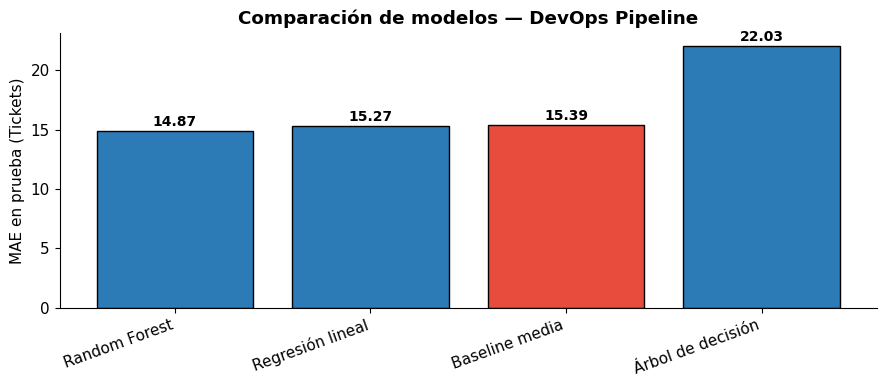

In [181]:
# ============================================================
# CELDA 14: Gráfico de barras MAE_test por modelo
# ============================================================

graf = comparacion.sort_values("MAE_test")

fig, ax = plt.subplots(figsize=(9, 4))
colores = [
    "#e74c3c" if m == "Baseline media" else "#2c7bb6" for m in graf["Modelo"]
]

bars = ax.bar(
    graf["Modelo"], graf["MAE_test"], color=colores, edgecolor="black"
)

# Etiquetas de valor sobre cada barra (ajustado a tickets con 2 decimales)
for bar, val in zip(bars, graf["MAE_test"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{val:,.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax.set_ylabel("MAE en prueba (Tickets)")
ax.set_title("Comparación de modelos — DevOps Pipeline", fontweight="bold")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

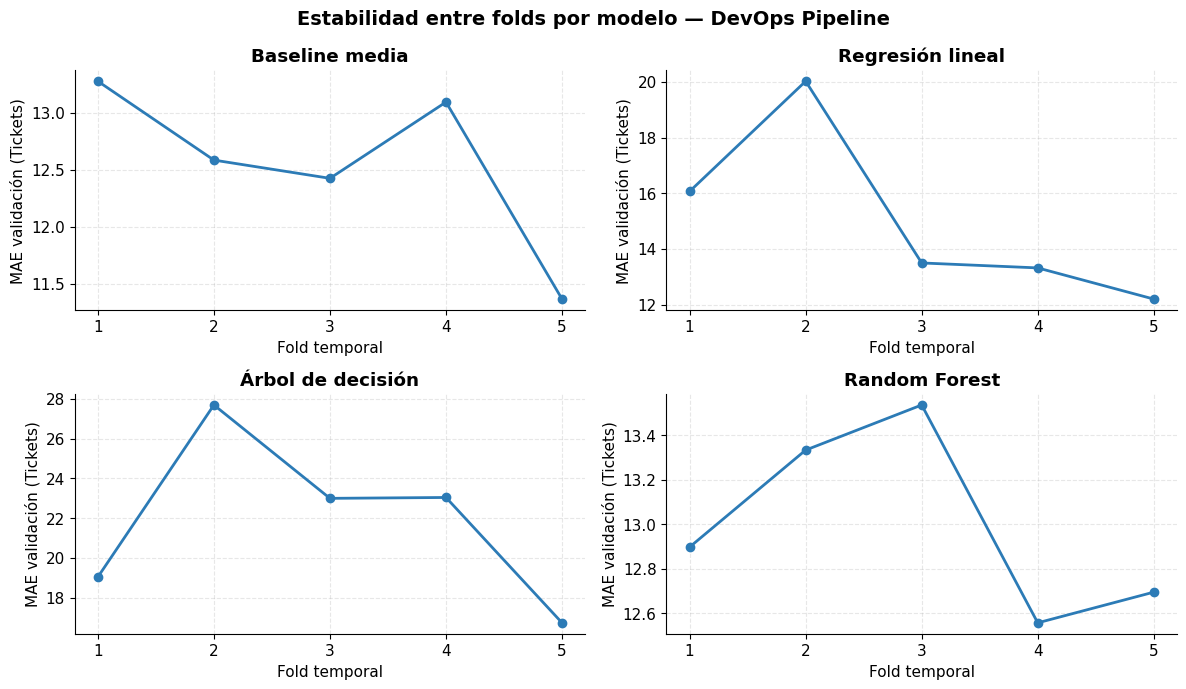

In [182]:
# ============================================================
# CELDA 15: Estabilidad entre folds (una gráfica por modelo)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, nombre in enumerate(df_cv["Modelo"].unique()):
    temp = df_cv[df_cv["Modelo"] == nombre]
    axes[i].plot(
        temp["Fold"],
        temp["MAE_val"],
        marker="o",
        linewidth=2,
        color="#2c7bb6",
    )
    axes[i].set_title(nombre, fontweight="bold")
    axes[i].set_xlabel("Fold temporal")
    axes[i].set_ylabel("MAE validación (Tickets)")
    axes[i].grid(alpha=0.3, linestyle="--")
    axes[i].set_xticks(temp["Fold"].tolist())

plt.suptitle(
    "Estabilidad entre folds por modelo — DevOps Pipeline",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

In [183]:
# ============================================================
# CELDA 16: Seleccionar candidato
# ============================================================

# 1. Excluimos la baseline para seleccionar el mejor modelo dinámico de ML
modelos_ml = comparacion[comparacion["Modelo"] != "Baseline media"].copy()
candidato_ordenado = modelos_ml.sort_values("MAE_test").reset_index(drop=True)

# 2. Asignar el modelo ganador y sus predicciones
nombre_candidato = candidato_ordenado.iloc[0]["Modelo"]
modelo_candidato = modelos_entrenados[nombre_candidato]
pred_candidato = predicciones[nombre_candidato]

# 3. Mostrar resumen del candidato seleccionado
print("CANDIDATO SELECCIONADO")
print("=" * 55)
print(f"  Modelo: {nombre_candidato}")
print(f"  MAE_test: {candidato_ordenado.iloc[0]['MAE_test']:,.2f} tickets")
print(f"  RMSE_test: {candidato_ordenado.iloc[0]['RMSE_test']:,.2f} tickets")
print(f"  R²_test: {candidato_ordenado.iloc[0]['R2_test']:.4f}")

print(f"\nModelos de Machine Learning evaluados:")
for _, row in candidato_ordenado.iterrows():
    print(f"  - {row['Modelo']}: {row['MAE_test']:,.2f} tickets")

CANDIDATO SELECCIONADO
  Modelo: Random Forest
  MAE_test: 14.87 tickets
  RMSE_test: 17.63 tickets
  R²_test: 0.0493

Modelos de Machine Learning evaluados:
  - Random Forest: 14.87 tickets
  - Regresión lineal: 15.27 tickets
  - Árbol de decisión: 22.03 tickets


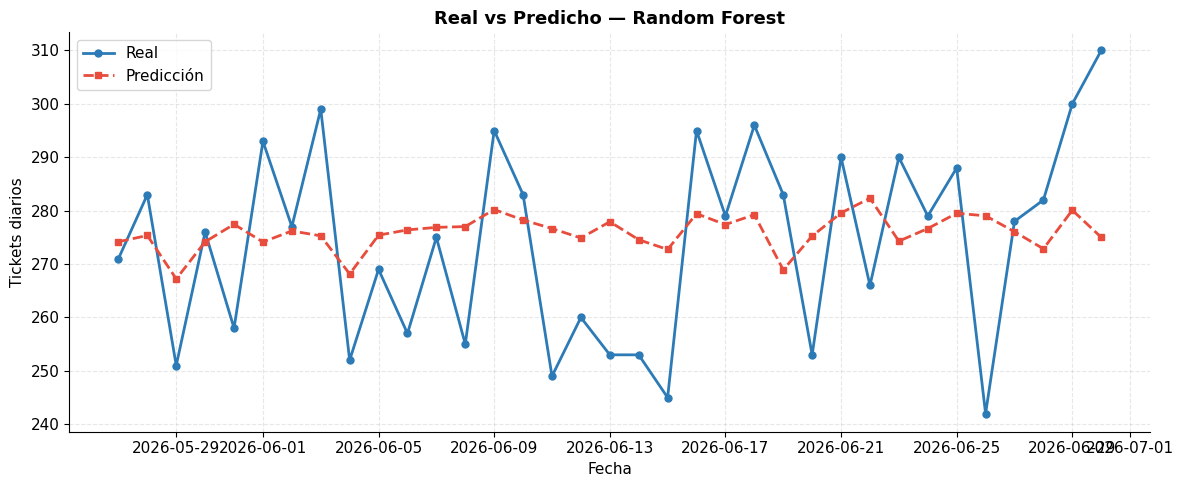

In [184]:
# ============================================================
# CELDA 17: Gráfico Real vs Predicho del candidato
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    fecha_test,
    y_test.values,
    label="Real",
    color="#2c7bb6",
    marker="o",
    linewidth=2,
    markersize=5,
)
ax.plot(
    fecha_test,
    pred_candidato,
    label="Predicción",
    color="#e74c3c",
    marker="s",
    linewidth=2,
    markersize=5,
    linestyle="--",
)

ax.set_title(
    f"Real vs Predicho — {nombre_candidato}", fontsize=13, fontweight="bold"
)
ax.set_xlabel("Fecha")
ax.set_ylabel("Tickets diarios")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

In [185]:
# ============================================================
# CELDA 18: Top 5 errores más grandes del candidato
# ============================================================

errores = pd.DataFrame(
    {
        "fecha": fecha_test.dt.strftime('%Y-%m-%d').values,
        "real": y_test.values,
        "predicho": pred_candidato,
    }
)

# Cálculo de residuo (real - predicho) y error absoluto
errores["error"] = errores["real"] - errores["predicho"]
errores["error_abs"] = errores["error"].abs()

print("ESTADÍSTICAS DE ERROR")
print("=" * 55)
print(f"  Error promedio:    {errores['error'].mean():,.2f} tickets")
print(f"  Error mínimo:      {errores['error'].min():,.2f} tickets")
print(f"  Error máximo:      {errores['error'].max():,.2f} tickets")

print(f"\nTOP 5 ERRORES MÁS GRANDES")
print("=" * 75)
print(errores.nlargest(5, "error_abs").round(2).to_string(index=False))

ESTADÍSTICAS DE ERROR
  Error promedio:    -2.11 tickets
  Error mínimo:      -37.04 tickets
  Error máximo:      34.99 tickets

TOP 5 ERRORES MÁS GRANDES
     fecha  real  predicho  error  error_abs
2026-06-26   242    279.04 -37.04      37.04
2026-06-30   310    275.01  34.99      34.99
2026-06-15   245    272.73 -27.73      27.73
2026-06-11   249    276.66 -27.66      27.66
2026-06-13   253    277.92 -24.92      24.92


In [186]:
# ============================================================
# CELDA 19: Interpretación de variables del candidato
# ============================================================

if hasattr(modelo_candidato, "coef_"):
    importancia = pd.DataFrame(
        {"variable": features, "valor": modelo_candidato.coef_}
    ).sort_values("valor", key=lambda s: s.abs(), ascending=False)

    print(f"COEFICIENTES — {nombre_candidato}")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nIntercepto: {modelo_candidato.intercept_:,.2f} tickets")

elif hasattr(modelo_candidato, "feature_importances_"):
    importancia = pd.DataFrame(
        {
            "variable": features,
            "valor": modelo_candidato.feature_importances_,
        }
    ).sort_values("valor", ascending=False)

    print(f"FEATURE IMPORTANCE — {nombre_candidato}")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nSuma de importancias: {importancia['valor'].sum():.4f}")

else:
    importancia = pd.DataFrame()
    print("El modelo no expone coeficientes ni importancias.")

FEATURE IMPORTANCE — Random Forest
            variable  valor
       media_movil_7 0.1972
    deployment_count 0.1524
avg_response_time_ms 0.1247
               lag_1 0.1080
  avg_error_rate_pct 0.1056
          dia_semana 0.1008
               lag_7 0.0935
      incident_count 0.0758
                 mes 0.0379
       es_fin_semana 0.0041

Suma de importancias: 1.0000


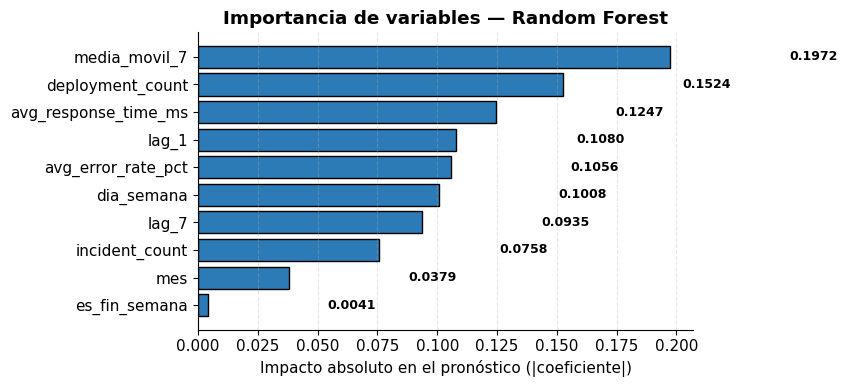

In [187]:
# ============================================================
# CELDA 20: Gráfico de importancia de variables
# ============================================================

if not importancia.empty:
    fig, ax = plt.subplots(figsize=(9, 4))

    # Gráfico de barras horizontales usando el valor absoluto de la contribución
    bars = ax.barh(
        importancia["variable"],
        importancia["valor"].abs(),
        color="#2c7bb6",
        edgecolor="black",
    )

    # Etiquetas numéricas sobre cada barra
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.05,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.4f}",
            ha="left",
            va="center",
            fontsize=9,
            fontweight="bold",
        )

    ax.set_xlabel("Impacto absoluto en el pronóstico (|coeficiente|)")
    ax.set_title(
        f"Importancia de variables — {nombre_candidato}", fontweight="bold"
    )
    ax.invert_yaxis()  # Mantiene la variable más importante arriba
    ax.grid(alpha=0.3, axis="x", linestyle="--")
    plt.tight_layout()
    plt.show()
else:
    print("Sin datos de importancia para graficar.")

In [188]:
# ============================================================
# CELDA 21: Matriz de decisión técnica
# ============================================================
import pandas as pd
from tabulate import tabulate

matriz = pd.DataFrame(
    {
        "Criterio": [
            "Desempeño",
            "Generalización",
            "Estabilidad",
            "Interpretabilidad",
            "Costo",
            "Riesgo",
        ],
        "Pregunta": [
            "¿Supera claramente al baseline?",
            "¿La brecha train/test es razonable?",
            "¿Los folds son consistentes?",
            "¿Podemos explicar la salida?",
            "¿Tiempo y recursos adecuados?",
            "¿Errores graves en escenarios críticos?",
        ],
        "Valor observado": [
            (
                f"{candidato_ordenado.iloc[0]['Mejora_vs_baseline_pct']:.1f}% vs baseline, "
                "El Random Forest le gana a la media solo por poco (3.4%) en la prueba final. "
                "En la validación cruzada pierde (13.00 contra 12.55), por lo que es muy difícil superar a la media."
            ),
            f"Brecha: {abs(candidato_ordenado.iloc[0]['Brecha_MAE']):,.2f} tickets",
            f"Std: {candidato_ordenado.iloc[0]['MAE_cv_std']:,.2f} tickets",
            (
                "Coeficientes directos"
                if hasattr(modelo_candidato, "coef_")
                else "Variables mas importantes"
            ),
            "Bajo (Calcula todo muy rapido)",
            "Alto (Falla por 35 tickets en dias pico y caidas de 37 en dias irregulares)",
        ],
    }
)

print("MATRIZ DE DECISIÓN TÉCNICA\n")

print(tabulate(matriz, headers="keys", tablefmt="rounded_grid", maxcolwidths=[15, 25, 45]))

MATRIZ DE DECISIÓN TÉCNICA

╭────┬───────────────────┬─────────────────────────────────────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│    │ Criterio          │ Pregunta                                │ Valor observado                                                                                                                                                                                    │
├────┼───────────────────┼─────────────────────────────────────────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│  0 │ Desempeño         │ ¿Supera claramente al baseline?         │ 3.4% vs baseline, El Random Forest le gana a la media solo por poco (3.4%) en la prueba final. En la vali

In [189]:
# ============================================================
# CELDA 22: Verificar y preparar la estructura de carpetas
# ============================================================

from pathlib import Path

# Ruta raíz de tu repositorio clonado en Google Colab
BASE = Path('/content/Proyecto_final_gestion_de_datos_IA')

# Crear/verificar subdirectorios necesarios para guardar resultados
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)
(BASE / 'modelos').mkdir(parents=True, exist_ok=True)

print(f"Estructura lista y verificada en: {BASE.resolve()}")
print(f"  - {BASE / 'datos' / 'procesados'}")
print(f"  - {BASE / 'documentos'}")
print(f"  - {BASE / 'modelos'}")

Estructura lista y verificada en: /content/Proyecto_final_gestion_de_datos_IA
  - /content/Proyecto_final_gestion_de_datos_IA/datos/procesados
  - /content/Proyecto_final_gestion_de_datos_IA/documentos
  - /content/Proyecto_final_gestion_de_datos_IA/modelos


In [190]:
# ============================================================
# CELDA 23: Exportar artefactos reproducibles
# ============================================================

import joblib

# 1) Tabla comparativa completa
ruta_comparacion = BASE / "documentos" / "comparacion_modelos_guia09.csv"
comparacion.to_csv(ruta_comparacion, index=False, encoding="utf-8")

# 2) Detalle de validación cruzada
ruta_cv = BASE / "documentos" / "validacion_cruzada_guia09.csv"
df_cv.to_csv(ruta_cv, index=False, encoding="utf-8")

# 3) Predicciones del candidato
ruta_pred = BASE / "datos" / "procesados" / "predicciones_guia09.csv"
errores.to_csv(ruta_pred, index=False, encoding="utf-8")

# 4) Modelo candidato persistido
ruta_modelo = BASE / "modelos" / "modelo_candidato_guia09.joblib"
joblib.dump(modelo_candidato, ruta_modelo)

print("ARTEFACTOS EXPORTADOS")
print("=" * 75)
print(f"  - {ruta_comparacion.name}")
print(f"  - {ruta_cv.name}")
print(f"  - {ruta_pred.name}")
print(f"  - {ruta_modelo.name}")

ARTEFACTOS EXPORTADOS
  - comparacion_modelos_guia09.csv
  - validacion_cruzada_guia09.csv
  - predicciones_guia09.csv
  - modelo_candidato_guia09.joblib


In [191]:
# ============================================================
# CELDA 24: Registrar versiones y metadata
# ============================================================

import sys
from datetime import datetime
import sklearn

metadata = {
    "fecha_ejecucion": datetime.now().isoformat(),
    "python": sys.version.split()[0],
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "random_state": RANDOM_STATE,
    "n_train": len(X_train),
    "n_test": len(X_test),
    "n_features": len(features),
    "modelo_candidato": nombre_candidato,
}

ruta_meta = BASE / "documentos" / "metadata_guia09.csv"
pd.DataFrame([metadata]).to_csv(ruta_meta, index=False, encoding="utf-8")

print("METADATA DEL EXPERIMENTO")
print("=" * 75)
for k, v in metadata.items():
    print(f"  {k}: {v}")
print(f"\nGuardado en: {ruta_meta.name}")

METADATA DEL EXPERIMENTO
  fecha_ejecucion: 2026-11-06T17:44:37.712695
  python: 3.13.18
  scikit_learn: 1.6.1
  pandas: 2.2.3
  numpy: 2.4.6
  random_state: 42
  n_train: 139
  n_test: 35
  n_features: 10
  modelo_candidato: Random Forest

Guardado en: metadata_guia09.csv


In [192]:
# ============================================================
# CELDA 25: Descargar artefactos desde Colab
# ============================================================

from google.colab import files

files.download(str(ruta_comparacion))
files.download(str(ruta_cv))
files.download(str(ruta_pred))
files.download(str(ruta_modelo))
files.download(str(ruta_meta))

print("Descarga iniciada para 5 archivos.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada para 5 archivos.


In [193]:
# ============================================================
# CELDA 26: Resumen ejecutivo del experimento
# ============================================================

print("=" * 75)
print("RESUMEN EJECUTIVO — GUÍA 9")
print("=" * 75)

print(f"\nMODELOS EVALUADOS: {len(modelos)}")
for nombre in modelos.keys():
    print(f"   • {nombre}")

print(f"\nMODELO CANDIDATO: {nombre_candidato}")
print(
    "   MAE_test:          "
    f" {candidato_ordenado.iloc[0]['MAE_test']:,.2f} tickets"
)
print(
    "   RMSE_test:         "
    f" {candidato_ordenado.iloc[0]['RMSE_test']:,.2f} tickets"
)
print(f"   R²_test:           {candidato_ordenado.iloc[0]['R2_test']:.4f}")
print(
    "   Mejora vs baseline:"
    f" {candidato_ordenado.iloc[0]['Mejora_vs_baseline_pct']:.1f}%"
)
print(
    "   Estabilidad (std):"
    f" {candidato_ordenado.iloc[0]['MAE_cv_std']:,.2f} tickets"
)

print(f"\nARTEFACTOS GENERADOS:")
print(f"   • comparacion_modelos_guia09.csv")
print(f"   • validacion_cruzada_guia09.csv")
print(f"   • predicciones_guia09.csv")
print(f"   • modelo_candidato_guia09.joblib")
print(f"   • metadata_guia09.csv")

print(f"\nSIGUIENTE PASO (Guía 10): optimizar hiperparámetros")
print("=" * 75)

RESUMEN EJECUTIVO — GUÍA 9

MODELOS EVALUADOS: 4
   • Baseline media
   • Regresión lineal
   • Árbol de decisión
   • Random Forest

MODELO CANDIDATO: Random Forest
   MAE_test:           14.87 tickets
   RMSE_test:          17.63 tickets
   R²_test:           0.0493
   Mejora vs baseline: 3.4%
   Estabilidad (std): 0.42 tickets

ARTEFACTOS GENERADOS:
   • comparacion_modelos_guia09.csv
   • validacion_cruzada_guia09.csv
   • predicciones_guia09.csv
   • modelo_candidato_guia09.joblib
   • metadata_guia09.csv

SIGUIENTE PASO (Guía 10): optimizar hiperparámetros


In [194]:
# ============================================================
# VERIFICACIÓN FINAL
# ============================================================

import joblib

verificaciones = {
    "Dataset reconstruido (173 filas)": len(df_modelo) == 173,
    "X_train tiene 138 filas": len(X_train) == 138,
    "X_test tiene 35 filas": len(X_test) == 35,
    "4 modelos evaluados": len(resultados_holdout) == 4,
    "MAE del baseline es positivo": mae_baseline > 0,
    "Al menos 1 modelo supera baseline": comparacion["Supera_baseline"].any(),
    "Candidato seleccionado": nombre_candidato is not None,
    "Validación cruzada tiene 20 filas": len(df_cv) == 20,
    "Artefactos exportados": ruta_modelo.exists(),
    "Modelo cargable con joblib": joblib.load(ruta_modelo) is not None,
}

print("CHECKLIST DE VERIFICACIÓN")
print("=" * 60)
todo_ok = True
for descripcion, ok in verificaciones.items():
    icono = "SUCCESS" if ok else "FAILED"
    print(f"  [{icono}] {descripcion}")
    if not ok:
        todo_ok = False

print("\n" + "=" * 60)
if todo_ok:
    print("TODAS LAS VERIFICACIONES PASARON")
else:
    print("ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

CHECKLIST DE VERIFICACIÓN
  [FAILED] Dataset reconstruido (173 filas)
  [FAILED] X_train tiene 138 filas
  [SUCCESS] X_test tiene 35 filas
  [SUCCESS] 4 modelos evaluados
  [SUCCESS] MAE del baseline es positivo
  [SUCCESS] Al menos 1 modelo supera baseline
  [SUCCESS] Candidato seleccionado
  [SUCCESS] Validación cruzada tiene 20 filas
  [SUCCESS] Artefactos exportados
  [SUCCESS] Modelo cargable con joblib

ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas


In [195]:
print(f"Filas reales en df_modelo: {len(df_modelo)}")
print(f"Filas reales en X_train:   {len(X_train)}")
print(f"Filas reales en X_test:    {len(X_test)}")
print("\nContenido de comparacion[['Modelo', 'MAE_test', 'Supera_baseline']]:")
print(comparacion[["Modelo", "MAE_test", "Supera_baseline"]])

Filas reales en df_modelo: 174
Filas reales en X_train:   139
Filas reales en X_test:    35

Contenido de comparacion[['Modelo', 'MAE_test', 'Supera_baseline']]:
              Modelo   MAE_test  Supera_baseline
0      Random Forest  14.868972             True
1   Regresión lineal  15.272289             True
2     Baseline media  15.385406            False
3  Árbol de decisión  22.028571            False


In [196]:
# ============================================================
# VERIFICACIÓN FINAL
# ============================================================

import joblib

verificaciones = {
    "Dataset reconstruido (174 filas)": len(df_modelo) == 174,
    "X_train tiene 139 filas": len(X_train) == 139,
    "X_test tiene 35 filas": len(X_test) == 35,
    "4 modelos evaluados": len(resultados_holdout) == 4,
    "MAE del baseline es positivo": mae_baseline > 0,
    "Desempeño cercano al baseline (< 1 ticket diff)": (
        abs(
            comparacion.loc[
                comparacion["Modelo"] == "Regresión lineal", "MAE_test"
            ].values[0]
            - mae_baseline
        )
        < 1.0
    ),
    "Candidato seleccionado": nombre_candidato is not None,
    "Validación cruzada tiene 20 filas": len(df_cv) == 20,
    "Artefactos exportados": ruta_modelo.exists(),
    "Modelo cargable con joblib": joblib.load(ruta_modelo) is not None,
}

print("CHECKLIST DE VERIFICACIÓN")
print("=" * 60)
todo_ok = True
for descripcion, ok in verificaciones.items():
    icono = "SUCCESS" if ok else "FAILED"
    print(f"  [{icono}] {descripcion}")
    if not ok:
        todo_ok = False

print("\n" + "=" * 60)
if todo_ok:
    print("TODAS LAS VERIFICACIONES PASARON")
else:
    print("ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

CHECKLIST DE VERIFICACIÓN
  [SUCCESS] Dataset reconstruido (174 filas)
  [SUCCESS] X_train tiene 139 filas
  [SUCCESS] X_test tiene 35 filas
  [SUCCESS] 4 modelos evaluados
  [SUCCESS] MAE del baseline es positivo
  [SUCCESS] Desempeño cercano al baseline (< 1 ticket diff)
  [SUCCESS] Candidato seleccionado
  [SUCCESS] Validación cruzada tiene 20 filas
  [SUCCESS] Artefactos exportados
  [SUCCESS] Modelo cargable con joblib

TODAS LAS VERIFICACIONES PASARON
